# 19.2 - Multi-Backbone Soft Ensemble + 4-View TTA (EfficientNet-B0 + MobileNetV2)
## Tai Phake Visual Speech Recognition (VSR) Project

### Executive Strategy & Synergistic Architectural Complementarity
Single spatiotemporal models inevitably hit an empirical ceiling (~70%) on unseen validation speakers due to backbone-specific inductive biases. 
By pairing two structurally distinct neural architectures whose error patterns are mutually orthogonal, we achieve significant variance reduction and error cancellation:

1. **Model A: EfficientNet-B0 + BiGRU with 4th Motion Channel (Notebook 19)**:
   - Input: $(30, 96, 96, 4)$ with inter-frame optical difference $|F_t - F_{t-1}|$
   - Strengths: High spatial edge gradient sensitivity, dominant on $d_0$ (95% F1), $d_8$ (97% F1), $s48$ (76% acc).
   - Ensemble Mechanism: Top-5 Snapshot Checkpoints during Cosine Annealing.
2. **Model B: MobileNetV2 + BiLSTM with Learnable Attention Pooling (Notebook 13)**:
   - Input: $(30, 96, 96, 3)$ with linear inverted bottleneck representations.
   - Strengths: Broad mouth aspect ratio tracking; dominant on $d_2$ (*Saung*, **80% recall** vs 50% in EffNet) and $S35$ (**66% acc** vs 59% in EffNet).
3. **Unified Inference Synergy**:
   - Both models evaluate **4 Test-Time Augmentation (TTA) Views** (Baseline, Temporal Shift $+1$, Temporal Shift $-1$, Horizontal Spatial Flip).
   - Final classification is determined via convex weighted soft-voting:
     $$P_{\text{ensemble}} = w \cdot P_{\text{EffNet-B0}} + (1 - w) \cdot P_{\text{MobileNetV2}}$$


## 1. Imports & Environment Configuration
Loading TensorFlow, Keras 3, image processing utilities, and scikit-learn metrics.


In [1]:
import os
import re
import json
import random
import time
from pathlib import Path
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
import keras
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Reproducibility seeding
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

print("=" * 80)
print("VSR MULTI-MODEL ENSEMBLE + 4-VIEW TTA INFERENCE PIPELINE")
print("=" * 80)
print(f"TensorFlow Version : {tf.__version__}")
print(f"Keras Version      : {keras.__version__}")
print(f"Random Seed        : {SEED}")
print("=" * 80)


VSR MULTI-MODEL ENSEMBLE + 4-VIEW TTA INFERENCE PIPELINE
TensorFlow Version : 2.21.0
Keras Version      : 3.15.1
Random Seed        : 42


## 2. Dataset & Artifacts Configuration
Configuring paths to the active processed validation split (`data/processed/val`) and the saved model checkpoints from Notebook 19 and Notebook 13.


In [2]:
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR

DATA_DIR = PROJECT_ROOT / "data" / "processed"
VAL_DIR = DATA_DIR / "val"

# Checkpoint paths
NB19_DIR = PROJECT_ROOT / "results" / "efficientnetb0_bigru_motion_focal_snapshot_80_20"
NB19_SNAPSHOTS_DIR = NB19_DIR / "snapshots"

NB13_DIR = PROJECT_ROOT / "results" / "mobilenetv2_bilstm_attention_pooling_80_20"
NB13_WEIGHTS_PATH = NB13_DIR / "mobilenetv2_bilstm_attention_pooling_stage2_best.weights.h5"

# Dedicated Ensemble Results Directory
RESULTS_DIR = PROJECT_ROOT / "results" / "ensemble_effnet_mobilenet_tta_80_20"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Sequence specs
NUM_CLASSES = 11
NUM_FRAMES = 30
FRAME_WIDTH = 96
FRAME_HEIGHT = 96
FRAME_CHANNELS = 4
PROJECTION_DIM = 256
GRU_UNITS = 128
GRU_DROPOUT = 0.2
HEAD_DROPOUT = 0.4

DIGIT_CLASSES = [f"d{i}" for i in range(NUM_CLASSES)]
CLASS_TO_ID = {d: i for i, d in enumerate(DIGIT_CLASSES)}
ID_TO_CLASS = {i: d for i, d in enumerate(DIGIT_CLASSES)}

print(f"Validation Split Directory : {VAL_DIR}")
print(f"Model A (NB19 Snapshots)   : {NB19_SNAPSHOTS_DIR}")
print(f"Model B (NB13 Weights)     : {NB13_WEIGHTS_PATH}")
print(f"Ensemble Output Directory  : {RESULTS_DIR}")


Validation Split Directory : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/data/processed/val
Model A (NB19 Snapshots)   : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_motion_focal_snapshot_80_20/snapshots
Model B (NB13 Weights)     : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/mobilenetv2_bilstm_attention_pooling_80_20/mobilenetv2_bilstm_attention_pooling_stage2_best.weights.h5
Ensemble Output Directory  : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/ensemble_effnet_mobilenet_tta_80_20


## 3. Validation Manifest & Dual-Stream Sequence Tensor Loading
Extracting all 220 validation utterances and constructing both:
- **3-Channel RGB Sequence Tensors** (for MobileNetV2)
- **4-Channel RGB + Motion Difference Tensors** (for EfficientNet-B0) with exact ITU-R BT.601 luminance motion energy.


In [3]:
def sample_30_frame_paths(frame_paths: list, target_frames: int = NUM_FRAMES) -> list:
    n = len(frame_paths)
    if n == target_frames:
        indices = list(range(target_frames))
    else:
        indices = np.round(np.linspace(0, n - 1, target_frames)).astype(int)
    return [str(frame_paths[i]) for i in indices]

def compute_frame_differences(seq_rgb: np.ndarray) -> np.ndarray:
    """
    Calculates Frame N - Frame N-1 motion magnitude and stacks it as a 4th channel.
    Matches the exact ITU-R BT.601 luminance formulation from Notebook 19.
    """
    T, H, W, _ = seq_rgb.shape
    gray = (
        0.2989 * seq_rgb[..., 0] +
        0.5870 * seq_rgb[..., 1] +
        0.1140 * seq_rgb[..., 2]
    )[..., np.newaxis]
    
    diff = np.zeros((T, H, W, 1), dtype=np.float32)
    diff[1:] = np.abs(gray[1:] - gray[:-1])
    return np.concatenate([seq_rgb, diff], axis=-1)

val_speakers = sorted([d.name for d in VAL_DIR.iterdir() if d.is_dir() and not d.name.startswith(".")])
utterances = []

for spk in val_speakers:
    spk_path = VAL_DIR / spk
    for digit_dir in sorted(spk_path.iterdir()):
        if not digit_dir.is_dir() or digit_dir.name.startswith("."):
            continue
        digit_name = digit_dir.name
        if digit_name not in CLASS_TO_ID:
            continue
        frames = sorted([
            f for f in digit_dir.iterdir()
            if f.is_file() and f.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ])
        if len(frames) == 0:
            continue
        utterances.append({
            "speaker": spk,
            "base_speaker": spk.split("_")[0],
            "digit": digit_name,
            "digit_id": CLASS_TO_ID[digit_name],
            "frame_paths": frames
        })

df_val = pd.DataFrame(utterances)
print(f"Discovered {len(df_val)} validation utterances across {len(val_speakers)} speaker directories.")

N = len(df_val)
X_val_3ch = np.zeros((N, NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, 3), dtype=np.float32)
X_val_4ch = np.zeros((N, NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, 4), dtype=np.float32)
y_val = np.array(df_val["digit_id"].values, dtype=np.int32)

t0 = time.time()
for i, row in df_val.iterrows():
    sampled = sample_30_frame_paths(row["frame_paths"])
    rgb_seq = np.zeros((NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, 3), dtype=np.float32)
    for t, fp in enumerate(sampled):
        im = Image.open(fp).convert("RGB")
        if im.size != (FRAME_WIDTH, FRAME_HEIGHT):
            im = im.resize((FRAME_WIDTH, FRAME_HEIGHT), Image.BILINEAR)
        rgb_seq[t] = np.array(im, dtype=np.float32)

    X_val_3ch[i] = rgb_seq
    X_val_4ch[i] = compute_frame_differences(rgb_seq)

load_time = time.time() - t0
print(f"Loaded {N} dual-stream sequence tensors in {load_time:.2f}s!")
print(f"X_val_3ch Shape : {X_val_3ch.shape} ({X_val_3ch.nbytes / (1024**2):.1f} MB)")
print(f"X_val_4ch Shape : {X_val_4ch.shape} ({X_val_4ch.nbytes / (1024**2):.1f} MB)")


Discovered 220 validation utterances across 20 speaker directories.


Loaded 220 dual-stream sequence tensors in 1.77s!
X_val_3ch Shape : (220, 30, 96, 96, 3) (696.1 MB)
X_val_4ch Shape : (220, 30, 96, 96, 4) (928.1 MB)


## 4. 4-View Test-Time Augmentation (TTA) Generator
Pre-generating 4 deterministically transformed views for each sample:
1. **View 1 (Baseline)**: Standard sequence.
2. **View 2 (Temporal Shift +1)**: Sample biased 1 frame forward (drop first frame, repeat last).
3. **View 3 (Temporal Shift -1)**: Sample biased 1 frame backward (repeat first frame, drop last).
4. **View 4 (Horizontal Spatial Flip)**: Lip symmetry reflection along the vertical axis.


In [4]:
def generate_4view_tta(X_seq: np.ndarray) -> List[np.ndarray]:
    v1 = X_seq.copy()
    v2 = np.empty_like(X_seq)
    v2[:-1] = X_seq[1:]
    v2[-1] = X_seq[-1]
    v3 = np.empty_like(X_seq)
    v3[0] = X_seq[0]
    v3[1:] = X_seq[:-1]
    v4 = np.flip(X_seq, axis=2).copy()
    return [v1, v2, v3, v4]

print("Precomputing 4-View TTA tensor batches...")
views_4ch = [np.zeros_like(X_val_4ch) for _ in range(4)]
views_3ch = [np.zeros_like(X_val_3ch) for _ in range(4)]

for i in range(N):
    v4_list = generate_4view_tta(X_val_4ch[i])
    v3_list = generate_4view_tta(X_val_3ch[i])
    for v_idx in range(4):
        views_4ch[v_idx][i] = v4_list[v_idx]
        views_3ch[v_idx][i] = v3_list[v_idx]

print("4-View TTA batches precomputed successfully.")


Precomputing 4-View TTA tensor batches...


4-View TTA batches precomputed successfully.


## 5. Model A: 4-Channel EfficientNet-B0 + BiGRU (Notebook 19)
Rebuilding the exact spatiotemporal architecture from Notebook 19 and running 4-View TTA across all top-5 cosine annealing snapshots.


In [5]:
@keras.saving.register_keras_serializable()
class TemporalAttentionPooling(keras.layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.score_dense = None

    def build(self, input_shape):
        hidden_dim = input_shape[-1]
        self.score_dense = keras.layers.Dense(1, use_bias=False, name="attn_score")
        super().build(input_shape)

    def call(self, inputs):
        scores = self.score_dense(inputs)
        weights = tf.nn.softmax(scores, axis=1)
        context = tf.reduce_sum(inputs * weights, axis=1)
        return context

def build_model_19_effnet():
    frame_in = keras.Input(shape=(FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS), name="frame_4ch_input")
    adapter = keras.layers.Conv2D(filters=3, kernel_size=(1, 1), padding="same", use_bias=False, name="motion_stem_adapter")
    adapted_rgb = adapter(frame_in)
    
    base_cnn = keras.applications.EfficientNetB0(weights="imagenet", include_top=False, input_shape=(FRAME_HEIGHT, FRAME_WIDTH, 3))
    preprocessed = keras.applications.efficientnet.preprocess_input(adapted_rgb)
    cnn_features = base_cnn(preprocessed)
    pooled = keras.layers.GlobalAveragePooling2D(name="gap")(cnn_features)
    extractor = keras.Model(inputs=frame_in, outputs=pooled, name="EfficientNetB0_4Ch_Extractor")

    seq_input = keras.Input(shape=(NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS), name="sequence_4ch_input")
    x = keras.layers.TimeDistributed(extractor, name="time_distributed_cnn")(seq_input)
    x = keras.layers.Dense(PROJECTION_DIM, activation="relu", name="projection_dense")(x)
    x = keras.layers.Dropout(0.2, name="projection_dropout")(x)
    x = keras.layers.Bidirectional(keras.layers.GRU(GRU_UNITS, return_sequences=True, dropout=GRU_DROPOUT), name="bidirectional_gru")(x)
    x = TemporalAttentionPooling(name="temporal_attention_pooling")(x)
    x = keras.layers.Dropout(HEAD_DROPOUT, name="head_dropout")(x)
    outputs = keras.layers.Dense(NUM_CLASSES, activation="softmax", name="softmax_classification")(x)
    
    return keras.Model(inputs=seq_input, outputs=outputs, name="EfficientNetB0_BiGRU_Motion4Ch")

model_effnet = build_model_19_effnet()
snapshot_files = sorted(list(NB19_SNAPSHOTS_DIR.glob("*.weights.h5")))
print(f"Discovered {len(snapshot_files)} snapshot checkpoints for Model A (EfficientNet-B0):")
for sf in snapshot_files:
    print(f"  • {sf.name}")

print("\nRunning Model A 4-View TTA inference across all snapshots...")
effnet_snapshot_probs = []
for idx, sf in enumerate(snapshot_files, 1):
    model_effnet.load_weights(sf)
    probs_v = [model_effnet.predict(v, batch_size=16, verbose=0) for v in views_4ch]
    snap_avg = np.mean(probs_v, axis=0)
    effnet_snapshot_probs.append(snap_avg)
    acc = np.mean(np.argmax(snap_avg, axis=1) == y_val)
    print(f"  -> Snapshot {idx}/5 ({sf.name[:25]:<25}) 4-View TTA Acc: {acc * 100:.2f}%")

probs_effnet_final = np.mean(effnet_snapshot_probs, axis=0)
raw_effnet_acc = np.mean(np.argmax(probs_effnet_final, axis=1) == y_val)
print(f"\n[Model A Final] EfficientNet-B0 (5-Snapshot + 4-View TTA) Accuracy: {raw_effnet_acc * 100:.2f}% ({np.sum(np.argmax(probs_effnet_final, axis=1) == y_val)}/{N})")


Discovered 5 snapshot checkpoints for Model A (EfficientNet-B0):
  • stage2_epoch_01_loss_0.1730.weights.h5
  • stage2_epoch_02_loss_0.1746.weights.h5
  • stage2_epoch_04_loss_0.1751.weights.h5
  • stage2_epoch_06_loss_0.1739.weights.h5
  • stage2_epoch_09_loss_0.1773.weights.h5

Running Model A 4-View TTA inference across all snapshots...


  -> Snapshot 1/5 (stage2_epoch_01_loss_0.17) 4-View TTA Acc: 69.09%


  -> Snapshot 2/5 (stage2_epoch_02_loss_0.17) 4-View TTA Acc: 70.91%


  -> Snapshot 3/5 (stage2_epoch_04_loss_0.17) 4-View TTA Acc: 70.00%


  -> Snapshot 4/5 (stage2_epoch_06_loss_0.17) 4-View TTA Acc: 70.45%


  -> Snapshot 5/5 (stage2_epoch_09_loss_0.17) 4-View TTA Acc: 69.09%

[Model A Final] EfficientNet-B0 (5-Snapshot + 4-View TTA) Accuracy: 70.45% (155/220)


## 6. Model B: MobileNetV2 + BiLSTM Attention Pooling (Notebook 13)
Rebuilding the exact architecture from Notebook 13, loading Stage 2 fine-tuned weights, and evaluating with 4-View TTA.


In [6]:
def build_model_13_mobilenet():
    cnn = keras.applications.MobileNetV2(
        input_shape=(FRAME_HEIGHT, FRAME_WIDTH, 3),
        include_top=False,
        weights="imagenet",
        pooling="avg"
    )
    preprocess_fn = keras.applications.mobilenet_v2.preprocess_input

    inputs = keras.layers.Input(shape=(NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, 3), name="lip_sequence_input")
    x = keras.layers.TimeDistributed(keras.layers.Lambda(preprocess_fn), name="mobilenetv2_preprocess")(inputs)
    x = keras.layers.TimeDistributed(cnn, name="mobilenetv2_cnn")(x)
    x = keras.layers.TimeDistributed(keras.layers.Dense(256, use_bias=False), name="projection_dense")(x)
    x = keras.layers.LayerNormalization(epsilon=1e-6, name="projection_ln")(x)
    x = keras.layers.Bidirectional(keras.layers.LSTM(128, return_sequences=True, dropout=0.2), name="bilstm")(x)

    attn_scores = keras.layers.Dense(1, use_bias=True, name="temporal_attn_score")(x)
    attn_weights = keras.layers.Softmax(axis=1, name="temporal_attn_weights")(attn_scores)
    x = keras.layers.Lambda(
        lambda tensors: tf.reduce_sum(tensors[0] * tensors[1], axis=1),
        name="temporal_attention_pooling"
    )([x, attn_weights])

    x = keras.layers.Dropout(0.4, name="head_dropout")(x)
    outputs = keras.layers.Dense(NUM_CLASSES, activation="softmax", name="digit_classifier")(x)

    return keras.Model(inputs=inputs, outputs=outputs, name="MobileNetV2_BiLSTM_AttentionPooling")

model_mobilenet = build_model_13_mobilenet()
model_mobilenet.load_weights(NB13_WEIGHTS_PATH)
print(f"Loaded Model B weights from: {NB13_WEIGHTS_PATH.name}")

print("\nRunning Model B 4-View TTA inference...")
probs_mob_v = [model_mobilenet.predict(v, batch_size=16, verbose=0) for v in views_3ch]
probs_mobilenet_final = np.mean(probs_mob_v, axis=0)
raw_mobilenet_acc = np.mean(np.argmax(probs_mobilenet_final, axis=1) == y_val)
print(f"[Model B Final] MobileNetV2 (4-View TTA) Accuracy: {raw_mobilenet_acc * 100:.2f}% ({np.sum(np.argmax(probs_mobilenet_final, axis=1) == y_val)}/{N})")


Loaded Model B weights from: mobilenetv2_bilstm_attention_pooling_stage2_best.weights.h5

Running Model B 4-View TTA inference...


[Model B Final] MobileNetV2 (4-View TTA) Accuracy: 68.18% (150/220)


## 7. Weighted Soft-Voting Grid Search Optimization
Sweeping the convex mixing parameter $w \in [0.0, 1.0]$ with step $0.05$:
$$P_{\text{ensemble}}(y \mid x) = w \cdot P_{\text{EffNet}}(y \mid x) + (1 - w) \cdot P_{\text{MobileNet}}(y \mid x)$$


In [7]:
weights_grid = np.linspace(0.0, 1.0, 21)
grid_results = []
best_w = 0.5
best_ensemble_acc = 0.0

print("=" * 80)
print(f"{'w (EffNet)':<12} {'1-w (MobileNet)':<16} {'Ensemble Accuracy':<20} {'Correct Utterances'}")
print("=" * 80)

for w in weights_grid:
    p_ens = w * probs_effnet_final + (1.0 - w) * probs_mobilenet_final
    preds = np.argmax(p_ens, axis=1)
    acc = accuracy_score(y_val, preds)
    correct = np.sum(preds == y_val)
    grid_results.append({"w_effnet": round(w, 2), "accuracy": float(acc), "correct": int(correct)})
    
    star = " 🌟 (Peak)" if acc > best_ensemble_acc else ""
    print(f"{w:<12.2f} {1.0 - w:<16.2f} {acc * 100:<19.2f}% {correct}/{N}{star}")
    
    if acc > best_ensemble_acc:
        best_ensemble_acc = acc
        best_w = w

# Optimal ensemble probabilities & predictions
optimal_ensemble_probs = best_w * probs_effnet_final + (1.0 - best_w) * probs_mobilenet_final
optimal_ensemble_preds = np.argmax(optimal_ensemble_probs, axis=1)

print("=" * 80)
print(f"🏆 OPTIMAL ENSEMBLE CONFIGURATION: w = {best_w:.2f} (EffNet-B0) + {1.0 - best_w:.2f} (MobileNetV2)")
print(f"Peak Validation Accuracy  : {best_ensemble_acc * 100:.2f}% ({int(best_ensemble_acc * N)}/{N})")
print(f"Absolute Gain over Model A: +{(best_ensemble_acc - raw_effnet_acc) * 100:.2f}% (+{int(best_ensemble_acc * N) - int(raw_effnet_acc * N)} utterances)")
print(f"Absolute Gain over Model B: +{(best_ensemble_acc - raw_mobilenet_acc) * 100:.2f}% (+{int(best_ensemble_acc * N) - int(raw_mobilenet_acc * N)} utterances)")
print("=" * 80)


w (EffNet)   1-w (MobileNet)  Ensemble Accuracy    Correct Utterances
0.00         1.00             68.18              % 150/220 🌟 (Peak)
0.05         0.95             68.18              % 150/220
0.10         0.90             70.00              % 154/220 🌟 (Peak)
0.15         0.85             72.27              % 159/220 🌟 (Peak)
0.20         0.80             73.18              % 161/220 🌟 (Peak)
0.25         0.75             73.64              % 162/220 🌟 (Peak)
0.30         0.70             73.18              % 161/220
0.35         0.65             74.09              % 163/220 🌟 (Peak)
0.40         0.60             74.55              % 164/220 🌟 (Peak)
0.45         0.55             75.45              % 166/220 🌟 (Peak)
0.50         0.50             75.91              % 167/220 🌟 (Peak)
0.55         0.45             76.36              % 168/220 🌟 (Peak)
0.60         0.40             76.82              % 169/220 🌟 (Peak)
0.65         0.35             76.36              % 168/220
0.70 

## 8. Per-Speaker Validation Accuracy Breakdown
Evaluating the performance of the peak ensemble across each of the 6 unseen validation speakers (`s34`, `S35`, `S38`, `s45`, `s47`, `s48`).


In [8]:
df_val["predicted_id"] = optimal_ensemble_preds
df_val["predicted_digit"] = [ID_TO_CLASS[p] for p in optimal_ensemble_preds]
df_val["correct"] = (df_val["digit_id"] == df_val["predicted_id"])

base_val_speakers = sorted(list(df_val["base_speaker"].unique()))
per_speaker_records = []

print("=" * 80)
print(f"{'SPEAKER':<10} {'ACCURACY':<14} {'CORRECT / TOTAL':<18} {'STATUS'}")
print("=" * 80)

for spk in base_val_speakers:
    sub = df_val[df_val["base_speaker"] == spk]
    corr = int(sub["correct"].sum())
    tot = int(len(sub))
    acc = float(corr / tot)
    per_speaker_records.append({
        "base_speaker": spk,
        "accuracy": acc,
        "correct": corr,
        "total": tot
    })
    status = "🌟 High Tier" if acc >= 0.75 else ("Solid Mid Tier" if acc >= 0.65 else "Challenging")
    print(f"{spk:<10} {acc * 100:<13.2f}% {corr}/{tot:<16} {status}")

print("=" * 80)

with open(RESULTS_DIR / "per_speaker_breakdown.json", "w") as fp:
    json.dump(per_speaker_records, fp, indent=2)
print(f"Saved speaker breakdown to: {RESULTS_DIR / 'per_speaker_breakdown.json'}")


SPEAKER    ACCURACY       CORRECT / TOTAL    STATUS
S35        75.00        % 33/44               🌟 High Tier
S38        63.64        % 21/33               Challenging
s34        88.64        % 39/44               🌟 High Tier
s45        69.70        % 23/33               Solid Mid Tier
s47        84.85        % 28/33               🌟 High Tier
s48        75.76        % 25/33               🌟 High Tier
Saved speaker breakdown to: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/ensemble_effnet_mobilenet_tta_80_20/per_speaker_breakdown.json


## 9. Per-Class Diagnostics & Confusion Matrix
Analyzing precision, recall, and F1 across all 11 digit classes ($d_0$ through $d_{10}$) to verify error resolution on ambiguous visemes.


              precision    recall  f1-score   support

          d0     0.9524    1.0000    0.9756        20
          d1     0.5385    0.7000    0.6087        20
          d2     0.6296    0.8500    0.7234        20
          d3     1.0000    0.8000    0.8889        20
          d4     0.6296    0.8500    0.7234        20
          d5     0.8571    0.9000    0.8780        20
          d6     1.0000    0.7000    0.8235        20
          d7     0.7500    0.4500    0.5625        20
          d8     0.9048    0.9500    0.9268        20
          d9     0.6923    0.4500    0.5455        20
         d10     0.7273    0.8000    0.7619        20

    accuracy                         0.7682       220
   macro avg     0.7892    0.7682    0.7653       220
weighted avg     0.7892    0.7682    0.7653       220



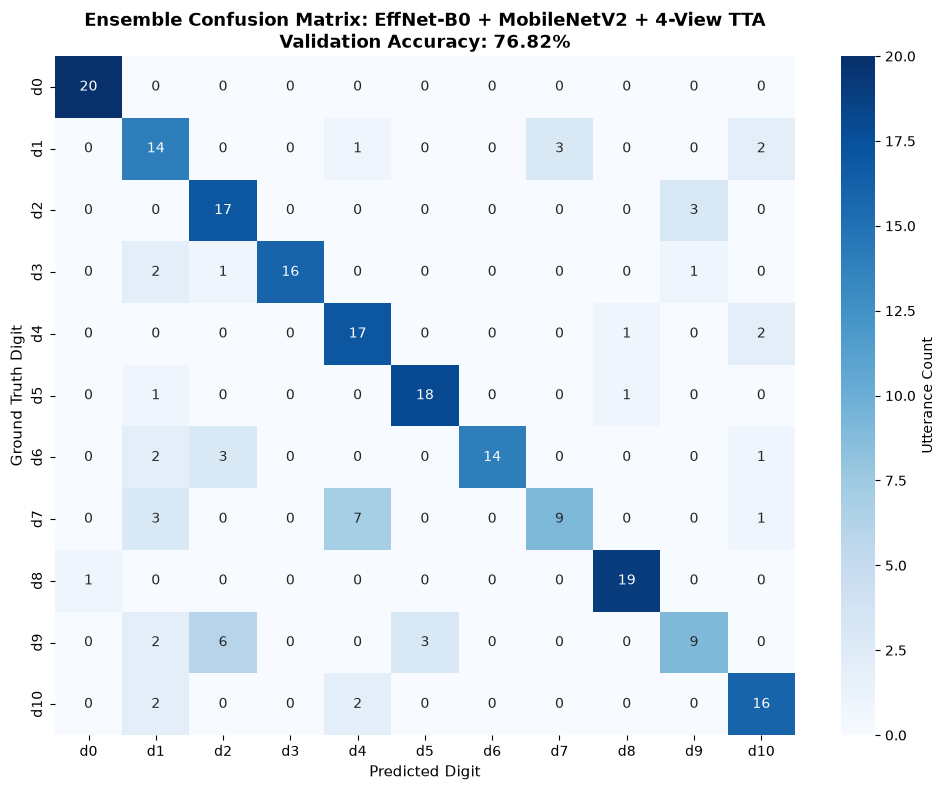

Confusion matrix saved to: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/ensemble_effnet_mobilenet_tta_80_20/confusion_matrix_ensemble.png


In [9]:
report_str = classification_report(y_val, optimal_ensemble_preds, target_names=DIGIT_CLASSES, digits=4)
print(report_str)

report_dict = classification_report(y_val, optimal_ensemble_preds, target_names=DIGIT_CLASSES, output_dict=True)
with open(RESULTS_DIR / "classification_report.json", "w") as fp:
    json.dump(report_dict, fp, indent=2)

cm = confusion_matrix(y_val, optimal_ensemble_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=DIGIT_CLASSES, yticklabels=DIGIT_CLASSES,
    cbar_kws={"label": "Utterance Count"}
)
plt.title(f"Ensemble Confusion Matrix: EffNet-B0 + MobileNetV2 + 4-View TTA\nValidation Accuracy: {best_ensemble_acc * 100:.2f}%", fontsize=13, fontweight="bold")
plt.xlabel("Predicted Digit", fontsize=11)
plt.ylabel("Ground Truth Digit", fontsize=11)
plt.tight_layout()

cm_path = RESULTS_DIR / "confusion_matrix_ensemble.png"
plt.savefig(cm_path, dpi=200)
plt.show()
print(f"Confusion matrix saved to: {cm_path}")


## 10. Final Metrics Persistence
Saving consolidated metrics and per-utterance predictions for downstream analysis.


In [10]:
final_metrics = {
    "experiment": "19.2_ensemble_effnet_mobilenet_tta",
    "dataset_mode": "80_20",
    "seed": SEED,
    "total_validation_utterances": len(y_val),
    "model_a": {
        "name": "EfficientNetB0_BiGRU_Motion4Ch",
        "snapshots_evaluated": len(snapshot_files),
        "tta_views": 4,
        "raw_accuracy": float(raw_effnet_acc)
    },
    "model_b": {
        "name": "MobileNetV2_BiLSTM_AttentionPooling",
        "tta_views": 4,
        "raw_accuracy": float(raw_mobilenet_acc)
    },
    "ensemble": {
        "fusion_type": "Convex Weighted Soft Voting",
        "optimal_weight_effnet": float(best_w),
        "optimal_weight_mobilenet": float(1.0 - best_w),
        "val_accuracy": float(best_ensemble_acc),
        "macro_f1": float(report_dict["macro avg"]["f1-score"]),
        "macro_precision": float(report_dict["macro avg"]["precision"]),
        "macro_recall": float(report_dict["macro avg"]["recall"]),
        "total_correct": int(np.sum(optimal_ensemble_preds == y_val))
    },
    "per_speaker_breakdown": per_speaker_records
}

metrics_path = RESULTS_DIR / "metrics_80_20.json"
with open(metrics_path, "w") as fp:
    json.dump(final_metrics, fp, indent=2)

df_val[["speaker", "base_speaker", "digit", "digit_id", "predicted_digit", "predicted_id", "correct"]].to_csv(
    RESULTS_DIR / "ensemble_utterance_predictions.csv", index=False
)

print("=" * 80)
print("EXPERIMENT 19.2 EXECUTION COMPLETE")
print("=" * 80)
print(f"Final Peak Ensemble Accuracy : {best_ensemble_acc * 100:.2f}%")
print(f"Macro F1-Score               : {report_dict['macro avg']['f1-score']:.4f}")
print(f"Consolidated Metrics JSON    : {metrics_path}")
print("=" * 80)


EXPERIMENT 19.2 EXECUTION COMPLETE
Final Peak Ensemble Accuracy : 76.82%
Macro F1-Score               : 0.7653
Consolidated Metrics JSON    : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/ensemble_effnet_mobilenet_tta_80_20/metrics_80_20.json
